# FloodSense exploratory data analysis

Explore the cleaned 2015–2017 training data. The held-out 2019 Imelda test set is not loaded or used.

In [21]:
import importlib
import sys
from pathlib import Path

project_root = next(
    (parent for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / "src" / "config.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the FloodSense project root from the notebook working directory.")
sys.path.insert(0, str(project_root))

import src.config
import src.data
import src.eda

importlib.reload(src.config)
importlib.reload(src.data)
importlib.reload(src.eda)

from src.config import NUMERIC_FEATURES
from src.data import load_clean, load_training

check_imperviousness = src.eda.check_imperviousness
class_summary = src.eda.class_summary
landcover_by_class = src.eda.landcover_by_class
plot_by_storm = src.eda.plot_by_storm
plot_correlation = src.eda.plot_correlation
plot_distributions = src.eda.plot_distributions
plot_map = src.eda.plot_map

eda_df = load_clean()
assert "imperviousness" not in NUMERIC_FEATURES
assert "imperviousness" not in eda_df.columns
assert "imperviousness" not in class_summary.__globals__["NUMERIC_FEATURES"]


Cleaned training data shape: (66514, 14)
Missing values by column:
year                   0
storm_name             0
storm_date             0
lat                    0
lon                    0
weight                 0
elevation_m            0
slope_degrees          0
distance_to_bayou_m    0
paved_pct              0
land_cover_type        0
rainfall_inches        0
flooded                0
grid_id                0


## 1. Numeric summary by flood class

Compare means, medians, and standard deviations for each configured numeric model feature between flooded and non-flooded examples.

In [22]:
class_summary(eda_df)


elevation_m                       slope_degrees                      \
               mean     median        std          mean    median       std   
flooded                                                                       
0         22.551327  20.741518  12.308434      2.465700  1.288525  3.723996   
1         17.196486  16.800722   5.031414      1.017012  0.762388  1.369267   

        distance_to_bayou_m                         paved_pct            \
                       mean      median         std      mean    median   
flooded                                                                   
0                388.087917  298.403710  347.096039  0.751299  0.899731   
1                535.474911  377.602414  501.273688  0.855612  1.000000   

                  rainfall_inches                      
              std            mean    median       std  
flooded                                                
0        0.307824        8.117876  7.940173  4.312380  
1        0.290510        8.742834  8.045193  3.787602

**My observations:** The cleaned data contains 33,955 flooded and 32,559 non-flooded examples. Flooded locations have lower median elevation (16.8 m vs. 20.7 m) and slope (0.76° vs. 1.29°), but a greater median distance to a bayou (378 m vs. 298 m). Their median paved percentage is higher (1.0 vs. 0.9), while median rainfall is similar (8.05 vs. 7.94 inches). 

## 2. Land cover by flood class

Compare counts for each land-cover category and see the class counts in the saved grouped bar chart.

Saved figure to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\landcover_by_class.png


flooded,0,1
land_cover_type,,
"Developed, High Intensity",4145,3134
"Developed, Low Intensity",10261,16404
"Developed, Medium Intensity",12833,12697
"Developed, Open Space",5320,1720


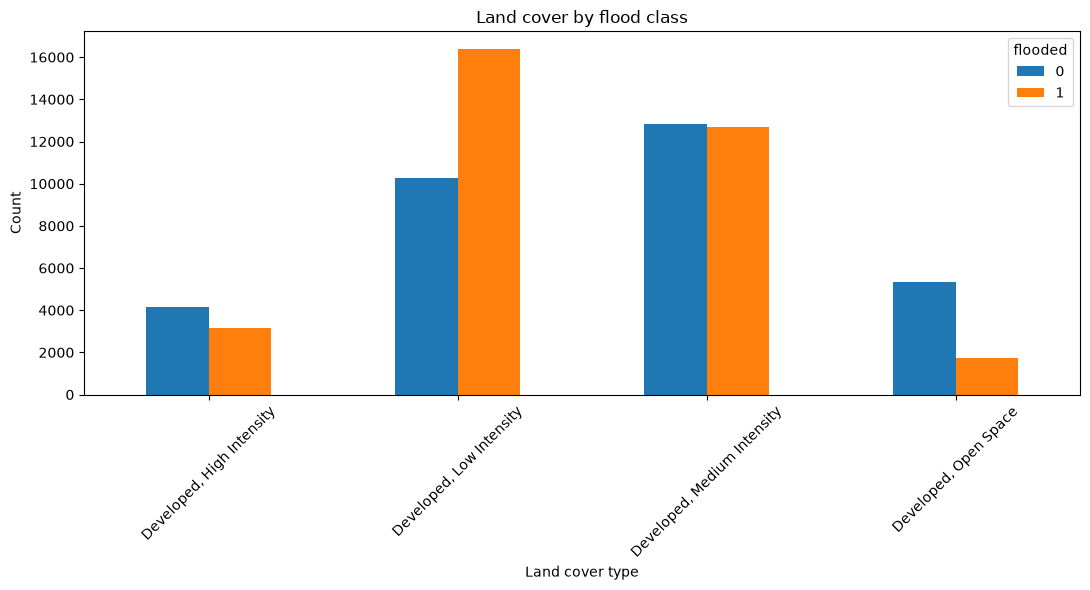

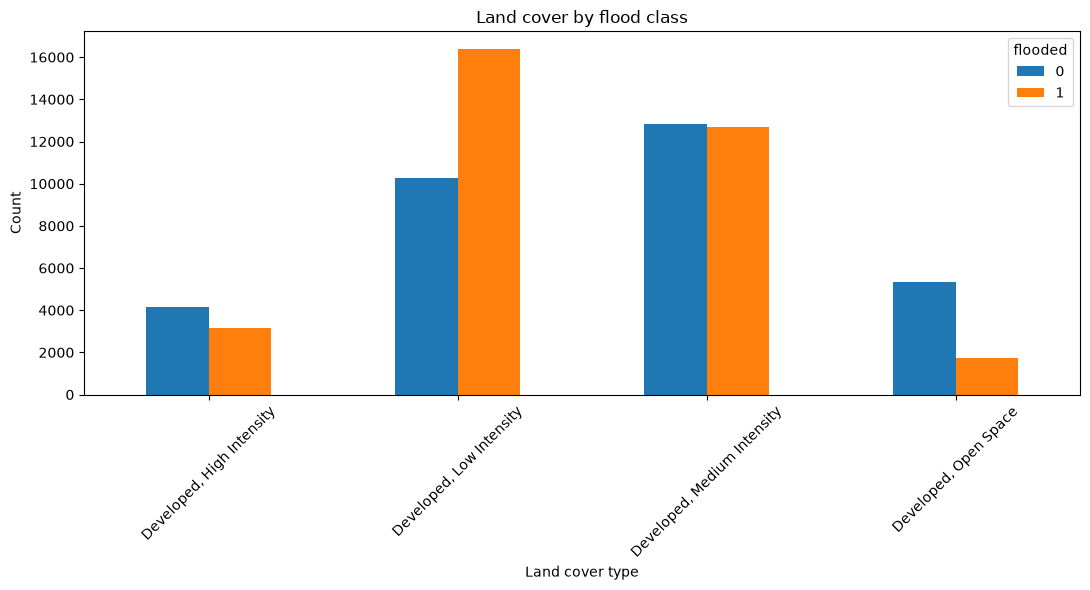

In [23]:
landcover_table, landcover_figure = landcover_by_class(eda_df)
display(landcover_table)
landcover_figure


**My observations:** Developed, Low Intensity has more flooded than non-flooded rows (16,404 vs. 10,261). Developed, Medium Intensity is nearly balanced (12,697 vs. 12,833), while High Intensity and Open Space have more non-flooded rows. The non-developed categories have only a few rows, all flooded; this follows the cleaning rule that retained every flooded row but filtered non-developed negative rows, so these counts do not represent the original land-cover distribution.

## 3. Numeric feature distributions

Overlay flooded and non-flooded histograms for the configured numeric features to compare their distributions.

Saved figure to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\feature_distributions.png


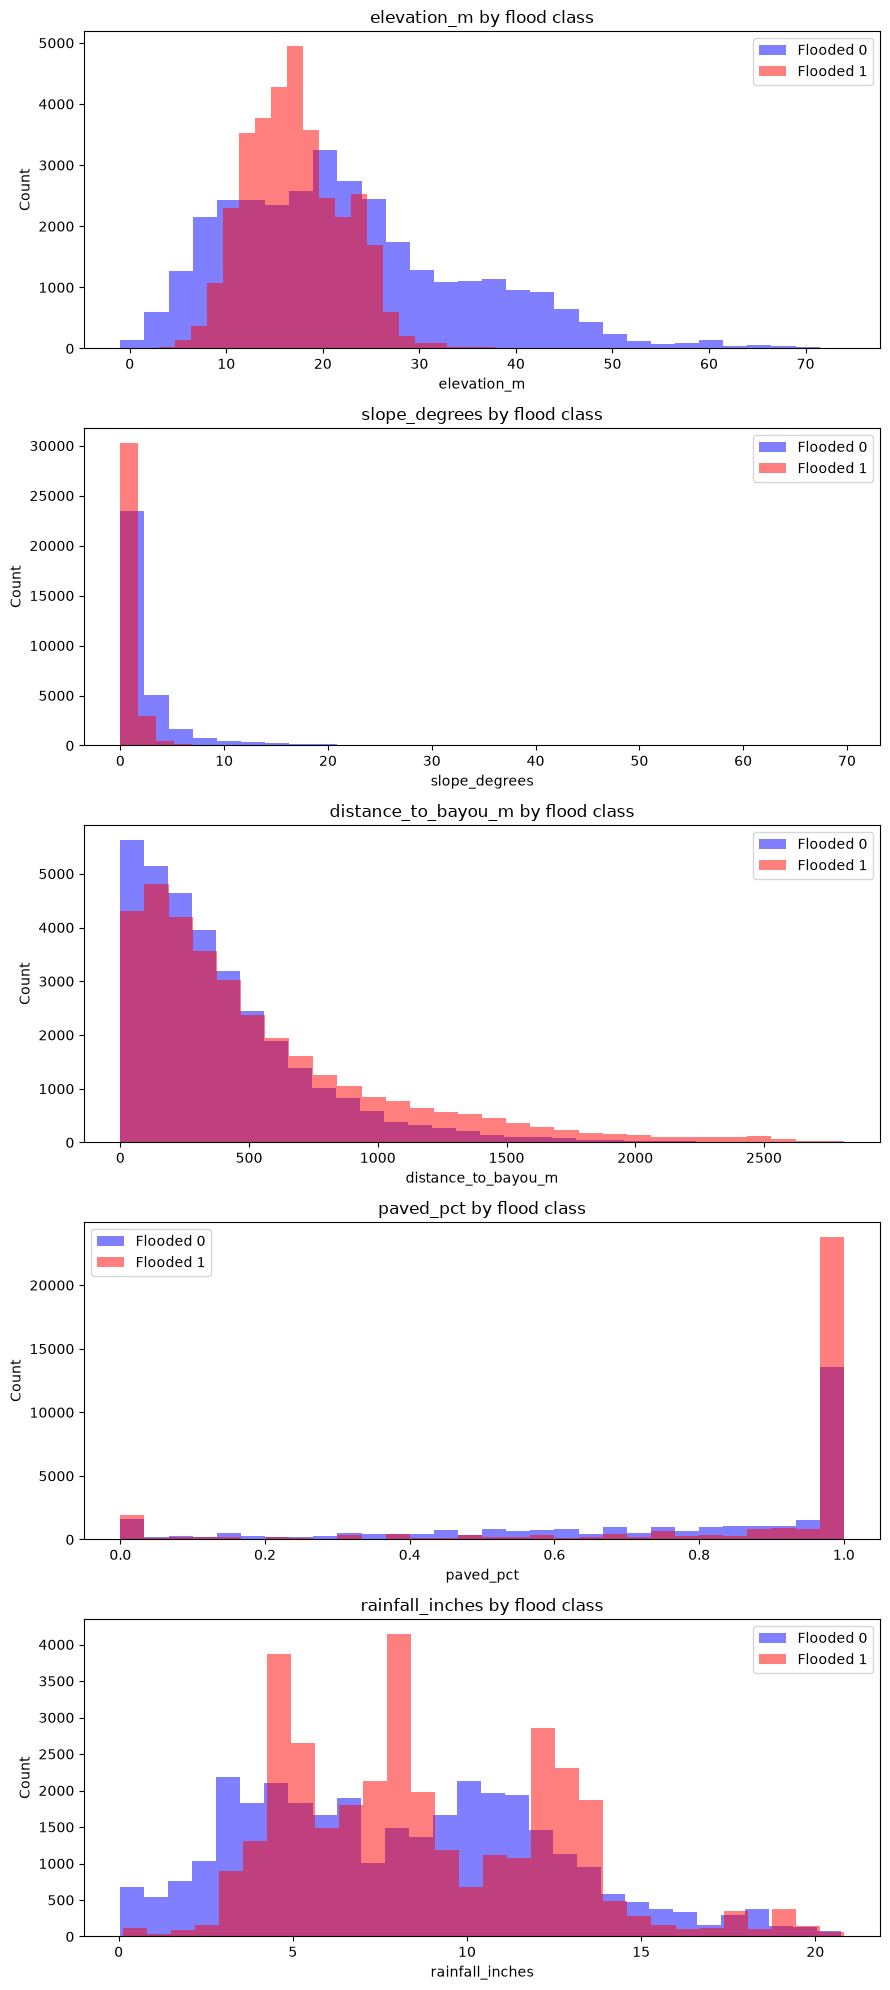

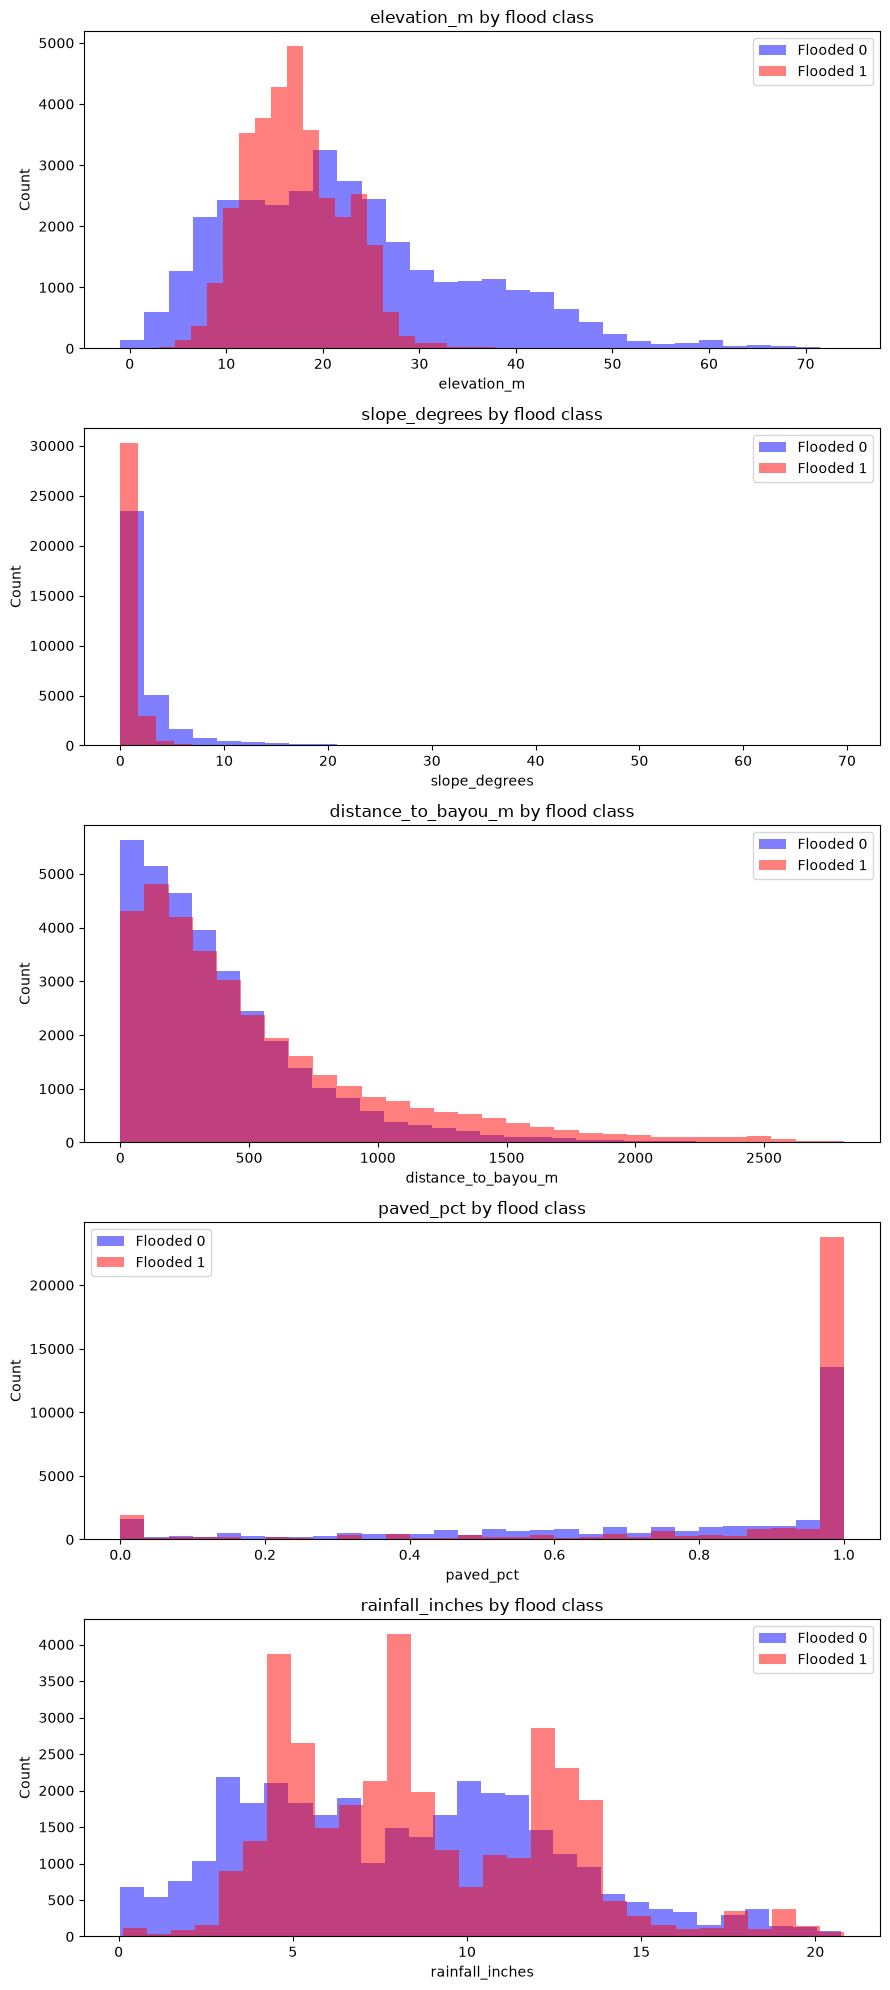

In [24]:
distribution_figure = plot_distributions(eda_df, NUMERIC_FEATURES)
distribution_figure


**My observations:** The five plotted feature distributions overlap substantially, so no single histogram cleanly separates the classes. Flooded rows are concentrated at lower elevations and slopes, while their distance-to-bayou distribution has a longer high-distance tail. Paved percentage is heavily concentrated at 1.0, especially for flooded rows. Rainfall overlaps broadly and has multiple peaks. Several features are skewed, so medians and distribution plots help complement the means.

## 4. Feature correlations

Inspect pairwise numeric correlations, including the flood target, as a descriptive check rather than a causal analysis.

Saved figure to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\feature_correlation.png


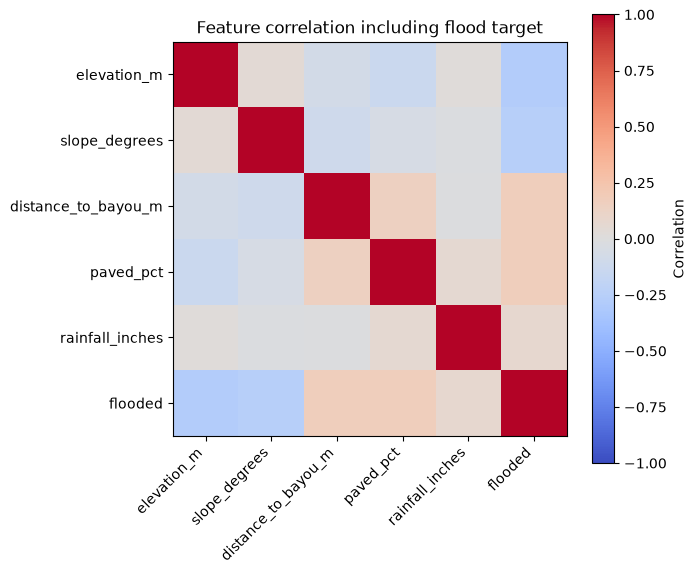

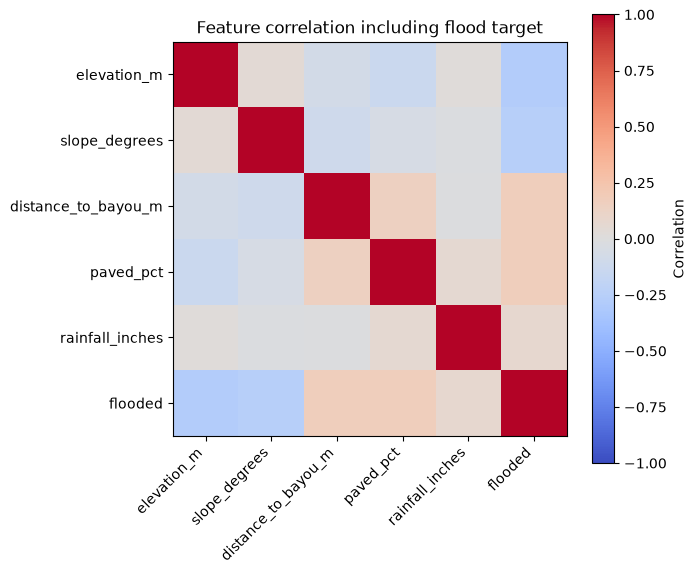

In [25]:
correlation_figure = plot_correlation(eda_df, NUMERIC_FEATURES)
correlation_figure


**My observations:** No plotted feature has a strong linear correlation with the target. Flooding has the largest absolute correlations with elevation (-0.276) and slope (-0.252), followed by distance to bayou (+0.168) and paved percentage (+0.172); rainfall is weakly correlated (+0.077) in this pooled dataset. The plotted numeric predictors are not strongly intercorrelated; correlation alone does not capture nonlinear effects or storm-specific patterns.

## 5. Rainfall by storm and flood class

Compare rainfall distributions across storms, with separate boxplots for flooded and non-flooded locations.

Saved figure to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\rainfall_by_storm.png


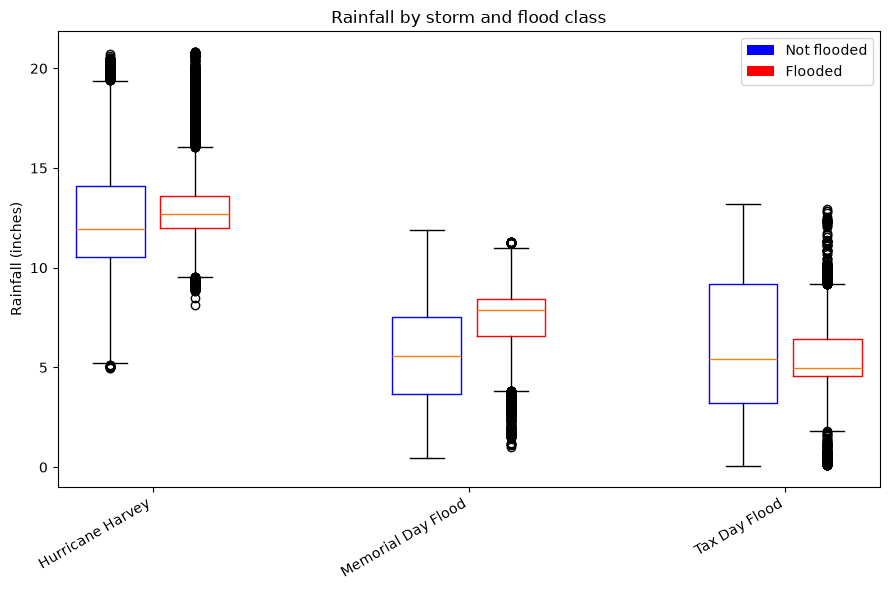

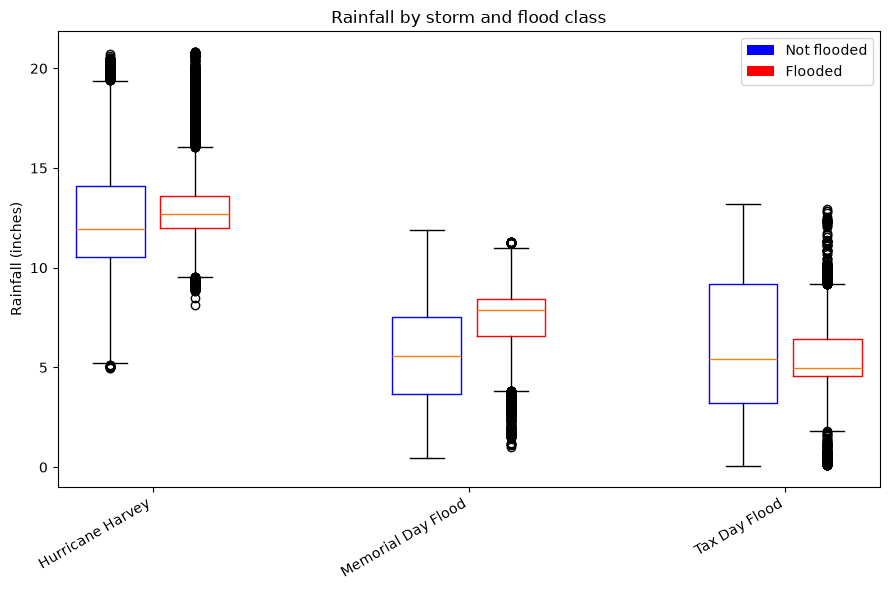

In [26]:
storm_figure = plot_by_storm(eda_df)
storm_figure


**My observations:** Flooded locations have higher mean rainfall for Hurricane Harvey (13.12 vs. 12.52 inches) and Memorial Day Flood (7.40 vs. 5.68 inches). Tax Day Flood shows the reverse, with a lower flooded mean (5.41 vs. 6.03 inches). Within each storm, rainfall distributions overlap, so rainfall alone does not distinguish every flooded location. Storm rainfall levels differ substantially, which is why comparisons should be made within storms as well as overall.

## 6. Geographic flood patterns

Map flooded locations in red and non-flooded locations in blue, with one panel for each storm.

Saved figure to C:\Users\ssaifudd\Downloads\AI-Flood Project\reports\figures\flood_locations_by_storm.png


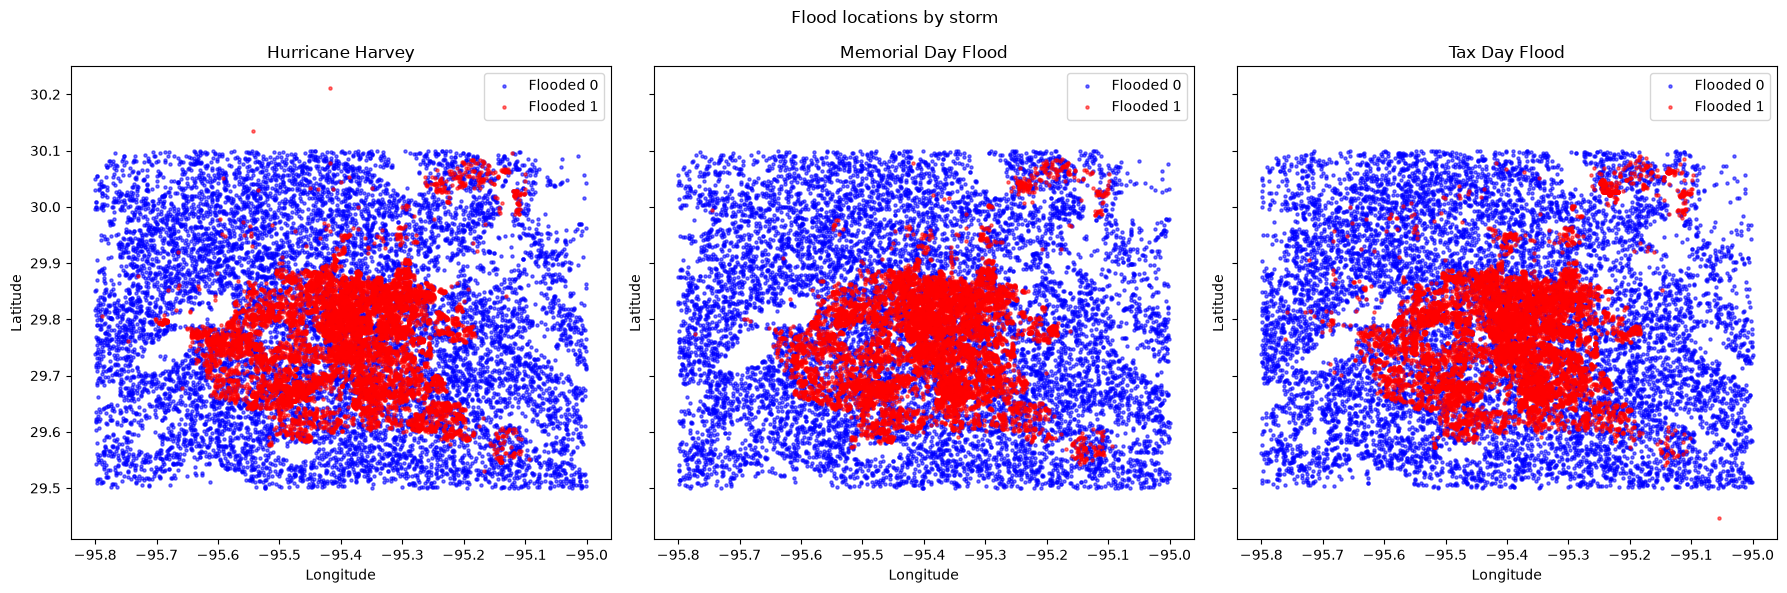

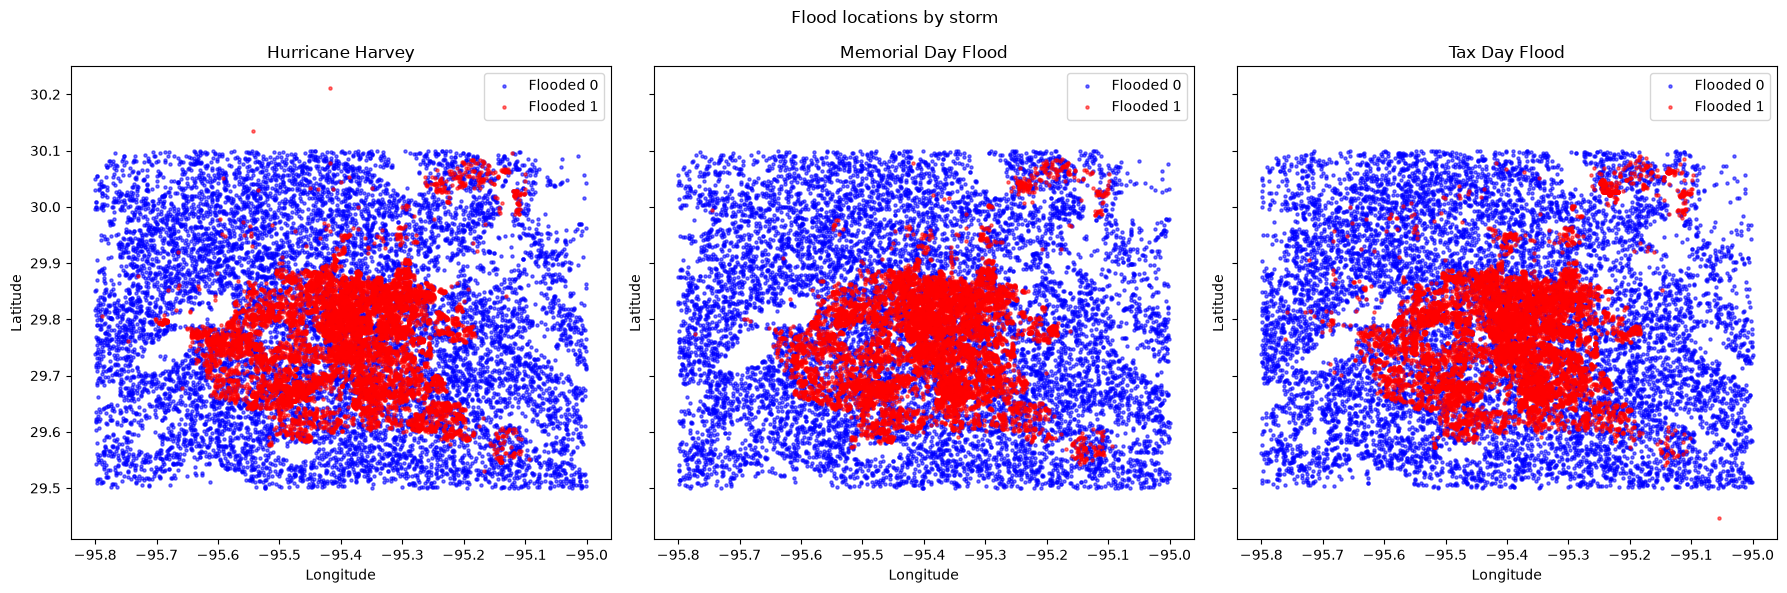

In [27]:
map_figure = plot_map(eda_df)
map_figure


**My observations:** In all three storm panels, flooded points (red) cluster most densely around central and southern parts of the plotted Houston area, while non-flooded points (blue) span a broader area. The red patterns overlap across storms but are not identical, and there are scattered flooded points outside the main clusters. These maps show spatial structure in the sampled locations; they do not establish that the same areas will flood in a future storm.